# <a id='toc1_'></a>[VI projekat: Klasifikator programskih jezika](#toc0_)

## <i>Saša Popović 237/2021 RSI</i>

**Table of contents**<a id='toc0_'></a>    
- [VI projekat: Klasifikator programskih jezika](#toc1_)    
- [Cilj projekta](#toc2_)    
- [Priprema](#toc3_)    
  - [Uvoz biblioteka](#toc3_1_)    
  - [Učitavanje dataset-a](#toc3_2_)    
- [Modeli](#toc4_)    
  - [SVM model sa 'bag-of-words' metodom](#toc4_1_)    
    - [Treniranje modela](#toc4_1_1_)    
    - [Performanse modela](#toc4_1_2_)    
  - [Multinomial Naive Bayes model sa TF-IDF metodom:](#toc4_2_)    
    - [Treniranje modela](#toc4_2_1_)    
    - [Performanse modela](#toc4_2_2_)    
  - [RandomForest model sa 'Leave One Out' unakrsnim vallidatorom](#toc4_3_)    
    - [Treniranje modela](#toc4_3_1_)    
    - [Performanse modela](#toc4_3_2_)    
  - [Korišćenje BART LLM - a sa ZeroShot klasifikatorom:](#toc4_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# <a id='toc2_'></a>[Cilj projekta](#toc0_)
Svrha projekta je istrenirati klasičan prediktivan model veštačke inteligencije koji će na osnovu unetog isečka koda prepoznati da li se radi o C, C++, C#, Java, Javascript ili Python kodu. Radi poređenja performansi istreniraćemo nekoliko klasičnih modela, koje ćemo potom uporediti sa lokalnim BERT modelom sa ZeroShot klasifikatorom.

# <a id='toc3_'></a>[Priprema](#toc0_)

## <a id='toc3_1_'></a>[Uvoz biblioteka](#toc0_)
Prvo uvozimo neophodne biblioteke:

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, LeaveOneOut
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## <a id='toc3_2_'></a>[Učitavanje dataset-a](#toc0_)

Zatim pomoću pandas biblioteke učitavamo podatke iz dataset - a u DataFrame objekat i ispisujemo njegove metapodatke i prvih par redova:

In [4]:
df = pd.read_csv('code_snippets.csv')
print(df.info())
df.head(5)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   code      600 non-null    object
 1   language  600 non-null    object
dtypes: object(2)
memory usage: 9.5+ KB
None


,code,language
0,"name = ""Alice""\nage = 25\nheight = 1.68\nis_st...",Python
1,"a = 10\nb = 3\nprint(a + b, a - b, a * b, a / ...",Python
2,"x = 7\nif x > 5:\n print(""Greater than 5"")\...",Python
3,"count = 0\nwhile count < 5:\n print(f""Count...",Python
4,"total = 0\nfor i in range(1, 11):\n total +...",Python


Potom razdvajamo features-e od klasa radi preglednosti:

In [ ]:
X,Y = df['code'], df['language']

# <a id='toc4_'></a>[Modeli](#toc0_)

Za treniranje i testiranje SVM i MultinomialNB modela, podelićemo podatke na fiksan train-test split u odnosu 80:20:

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, random_state=84, shuffle=True, train_size=0.8)

## <a id='toc4_1_'></a>[SVM model sa 'bag-of-words' metodom](#toc0_)

Kao primer jednog od osnovnih modela mašinskog učenja koji se mogu koristiti za procesiranje prirodnog jezika, istreniraćemo Support Vector model.

### <a id='toc4_1_1_'></a>[Treniranje modela](#toc0_)

Da bismo mogli da istreniramo model, potrebno je prvo konvertovati tekstualne podatke u numeričke. Za ovo ćemo koristiti CountVectorizer iz `sklearn.feature_extraction.text` modula.
CountVectorizer će prvo razbiti ulazni tekst na n-grame (dužine od 1 do n), i formirati rečnik svih n-grama na osnovu celog dataset-a. Potom će za svaki red iz dataset-a prebrojati koliko puta se svaki od n-grama pojavljuje u tom redu, čime dobijamo numerički (vektorski) ekvivalent tog reda.

In [ ]:
pipelineSVC = Pipeline([
    ('vectorizer', CountVectorizer(lowercase= True, ngram_range=(1,2))),
    ('classifier', SVC(random_state= 84))
])
count_vectorizer = CountVectorizer(lowercase= True, ngram_range=(1,2))
pipelineSVC.fit(x_train, y_train)


Pipeline(steps=[('vectorizer', CountVectorizer(ngram_range=(1, 2))),
                ('classifier', SVC(random_state=84))])

### <a id='toc4_1_2_'></a>[Performanse modela](#toc0_)

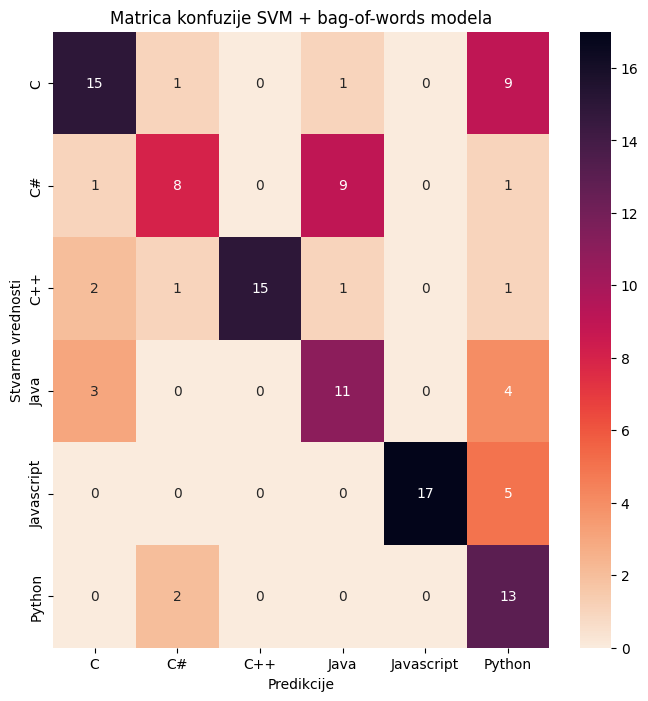

Performanse SVM + bag-of-words modela+:
Accuracy Score: 0.66
Classification report:
              precision    recall  f1-score   support

           C       0.71      0.58      0.64        26
          C#       0.67      0.42      0.52        19
         C++       1.00      0.75      0.86        20
        Java       0.50      0.61      0.55        18
  Javascript       1.00      0.77      0.87        22
      Python       0.39      0.87      0.54        15

    accuracy                           0.66       120
   macro avg       0.71      0.67      0.66       120
weighted avg       0.73      0.66      0.67       120



['SVC.pkl']

In [ ]:
modelSVC_pred = pipelineSVC.predict(x_test)
modelSVC_acc = accuracy_score(y_test, modelSVC_pred)
modelSVC_confmat = confusion_matrix(y_test, modelSVC_pred)
modelSVC_clr = classification_report(y_test, modelSVC_pred)
plt.figure(figsize=(8,8))
sns.heatmap(modelSVC_confmat,cmap='rocket_r',annot=True,xticklabels=pipelineSVC.classes_,yticklabels=pipelineSVC.classes_)
plt.title("Matrica konfuzije SVM + bag-of-words modela")
plt.xlabel("Predikcije")
plt.ylabel("Stvarne vrednosti")
plt.show()
print(f"Performanse SVM + bag-of-words modela+:\n" \
f"Accuracy Score: {modelSVC_acc:.2f}\nClassification report:\n{modelSVC_clr}")
joblib.dump(pipelineSVC,'SVC.pkl') #Pickling za kasniju upotrebu u Streamlit app

## <a id='toc4_2_'></a>[Multinomial Naive Bayes model sa TF-IDF metodom:](#toc0_)

### <a id='toc4_2_1_'></a>[Treniranje modela](#toc0_)

Za treniranje Multinomial Naive Bayes modela, koristićemo TF-IDF metodu vektorizacije teksta.

In [ ]:
pipelineMNB = Pipeline([
    ('vectorizer', TfidfVectorizer(lowercase= True)),
    ('classifier', MultinomialNB())
])
pipelineMNB.fit(x_train, y_train)

Pipeline(steps=[('vectorizer', TfidfVectorizer()),
                ('classifier', MultinomialNB())])

### <a id='toc4_2_2_'></a>[Performanse modela](#toc0_)

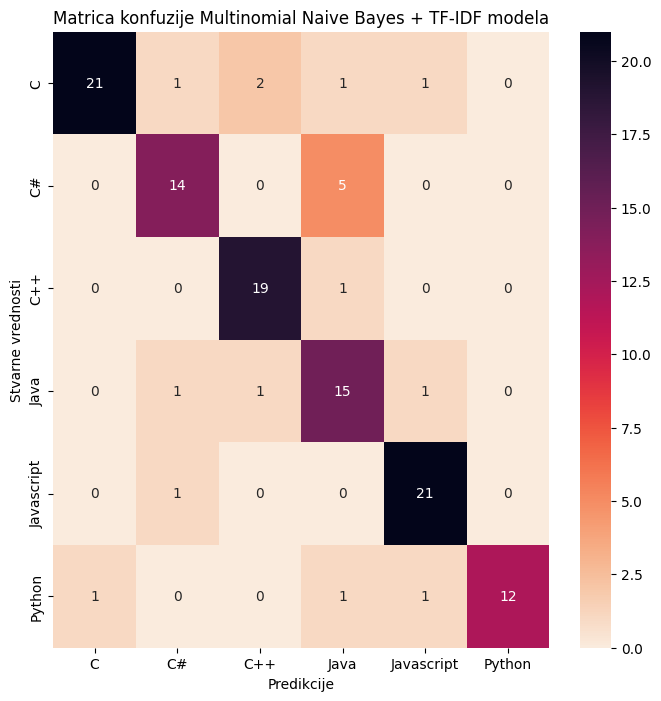

Performanse Multinomial Naive Bayes + TF-IDF modela:
Accuracy Score: 0.85
Classification report:
              precision    recall  f1-score   support

           C       0.95      0.81      0.88        26
          C#       0.82      0.74      0.78        19
         C++       0.86      0.95      0.90        20
        Java       0.65      0.83      0.73        18
  Javascript       0.88      0.95      0.91        22
      Python       1.00      0.80      0.89        15

    accuracy                           0.85       120
   macro avg       0.86      0.85      0.85       120
weighted avg       0.86      0.85      0.85       120



['MultinomialNB.pkl']

In [ ]:
modelMNB_pred = pipelineMNB.predict(x_test)
modelMNB_acc = accuracy_score(y_test, modelMNB_pred)
modelMNB_confmat = confusion_matrix(y_test, modelMNB_pred)
modelMNB_clr = classification_report(y_test, modelMNB_pred)
plt.figure(figsize=(8,8))
sns.heatmap(modelMNB_confmat,cmap='rocket_r',annot=True,xticklabels=pipelineMNB.classes_,yticklabels=pipelineMNB.classes_)
plt.title("Matrica konfuzije Multinomial Naive Bayes + TF-IDF modela")
plt.xlabel("Predikcije")
plt.ylabel("Stvarne vrednosti")
plt.show()
print(f"Performanse Multinomial Naive Bayes + TF-IDF modela:\n" \
f"Accuracy Score: {modelMNB_acc:.2f}\nClassification report:\n{modelMNB_clr}")
joblib.dump(pipelineMNB,'MultinomialNB.pkl') #Pickling za kasniju upotrebu u Streamlit app

## <a id='toc4_3_'></a>[RandomForest model sa 'Leave One Out' unakrsnim vallidatorom](#toc0_)

### <a id='toc4_3_1_'></a>[Treniranje modela](#toc0_)

Finalno, istreniraćemo RandomForest model, nad kojim ćemo iskoristiti LeaveOneOut pristup unakrsne validacije. Kod LeaveOneOut pristupa, model se u svakom koraku trenira nad svim primerima sem jednog, koji se koristi za testiranje. Ova metoda je korisna za vrlo male skupove podataka, ali je i računarski zahtevna jer se broj treniraja modela poklapa sa brojem primera.

Takođe ćemo primeniti i GridSearch tehniku, u cilju pronalaženja najboljih hiperparametara modela.

In [ ]:
tfidf_vectorizer = TfidfVectorizer(lowercase= True)
tfidf_vectorizer.fit(X)
X_vectorized = tfidf_vectorizer.transform(X)
modelRF= RandomForestClassifier(random_state= 84)
cv = LeaveOneOut()
params = {
    'n_estimators': [150],
    'criterion' : ['gini'],
    'max_depth' : [3, 5, 7],
    'max_features' : ['sqrt'],
    'min_samples_leaf': [1, 5, 10],
    'min_samples_split': [2, 10]
}
search = GridSearchCV(modelRF, params, cv=cv, scoring='accuracy', n_jobs=-1, verbose = 1)
search.fit(X_vectorized, Y)
pipelineRF = Pipeline([
    ('vectorizer', tfidf_vectorizer), #Unapred fitovan vektorizator
    ('classifier', search.best_estimator_)
])

Fitting 600 folds for each of 18 candidates, totalling 10800 fits


### <a id='toc4_3_2_'></a>[Performanse modela](#toc0_)

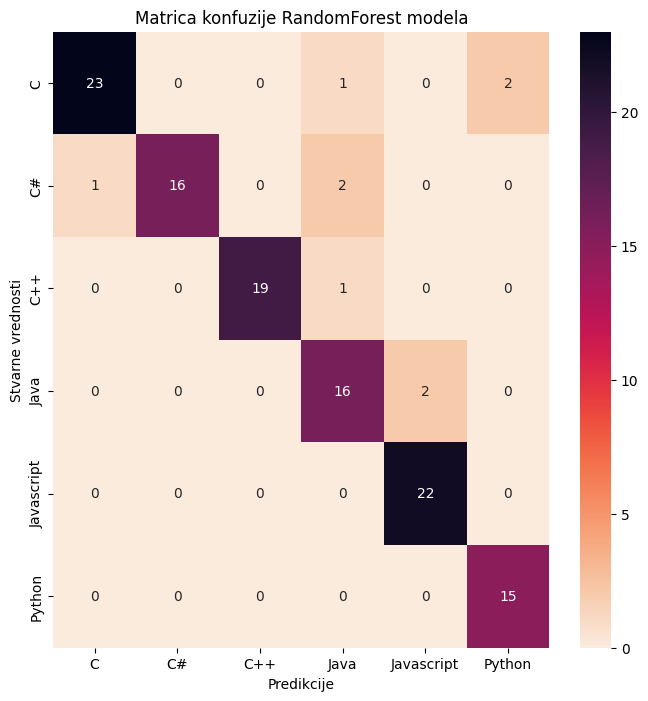

Performanse Multinomial Naive Bayes + TF-IDF modela:
Accuracy Score: 0.93
Classification report:
              precision    recall  f1-score   support

           C       0.96      0.88      0.92        26
          C#       1.00      0.84      0.91        19
         C++       1.00      0.95      0.97        20
        Java       0.80      0.89      0.84        18
  Javascript       0.92      1.00      0.96        22
      Python       0.88      1.00      0.94        15

    accuracy                           0.93       120
   macro avg       0.93      0.93      0.92       120
weighted avg       0.93      0.93      0.93       120

['Javascript']


['RandomForest.pkl']

In [ ]:
modelRF_pred = pipelineRF.predict(x_test)
modelRF_acc = accuracy_score(y_test, modelRF_pred)
modelRF_confmat = confusion_matrix(y_test, modelRF_pred)
modelRF_clr = classification_report(y_test, modelRF_pred)
plt.figure(figsize=(8,8))
sns.heatmap(modelRF_confmat,cmap='rocket_r',annot=True,xticklabels=pipelineRF.classes_,yticklabels=pipelineRF.classes_)
plt.title("Matrica konfuzije RandomForest modela")
plt.xlabel("Predikcije")
plt.ylabel("Stvarne vrednosti")
plt.show()
print(f"Performanse Multinomial Naive Bayes + TF-IDF modela:\n" \
f"Accuracy Score: {modelRF_acc:.2f}\nClassification report:\n{modelRF_clr}")
print(pipelineRF.predict(["""
async function getUser() {
  try {
    const res = await fetch('/api/user');
    const user = await res.json();
    console.log(user);
  } catch (e) {
    console.error('Failed to fetch user', e);
  }
}
"""]))
joblib.dump(pipelineRF,'RandomForest.pkl')

## <a id='toc4_4_'></a>[Korišćenje BART LLM - a sa ZeroShot klasifikatorom:](#toc0_)

Za kraj ćemo u cilju poređenja iskoristiti lokalni, unapred istrenirani BART LLM sa ZeroShot klasifikatorom. 
ZeroShot klasifikacija je tip zadatka gde model pokušava da predvidi klasu koju nije video prilikom treniranja.
Za razliku od OneShot ili FewShot klasifikacije, gde model prethodno dobija nekoliko primera uspešno obavljene klasifikacije, prilikom ZeroShot klasifikacije model dobija samo podatke čiju klasu treba da predvidi, i njihove moguće klase.

In [30]:
from transformers import pipeline

bert_zeroShot = pipeline(model= 'facebook/bart-large-mnli')
candidate_labels = ['Java', 'Javascript', 'C', 'C++', 'C#', 'Python']
input = """
async function getUser() {
  try {
    const res = await fetch('/api/user');
    const user = await res.json();
    console.log(user);
  } catch (e) {
    console.error('Failed to fetch user', e);
  }
}
"""
bert_zeroShot(input, candidate_labels, multi_label= False)

Device set to use cpu


{'sequence': "\nasync function getUser() {\n  try {\n    const res = await fetch('/api/user');\n    const user = await res.json();\n    console.log(user);\n  } catch (e) {\n    console.error('Failed to fetch user', e);\n  }\n}\n",
 'labels': ['C', 'Javascript', 'Python', 'Java', 'C++', 'C#'],
 'scores': [0.3748023509979248,
  0.2406500279903412,
  0.16468028724193573,
  0.08333224803209305,
  0.07366792112588882,
  0.06286708265542984]}

In [27]:
input=''' for i in range(1,10):
            x=x+1
'''
bert_zeroShot(input,candidate_labels, multi_label = False)

{'sequence': ' for i in range(1,10):\n            x=x+1\n',
 'labels': ['C', 'Python', 'Javascript', 'C++', 'Java', 'C#'],
 'scores': [0.36683931946754456,
  0.23582161962985992,
  0.12355194985866547,
  0.10214047878980637,
  0.09787556529045105,
  0.07377099990844727]}